# Chapter 14 — Wiener Processes and Itô's Lemma

Code behind the numbers in the chapter, in NumPy, with matplotlib for the figures. Every
random draw is seeded, so a rerun prints the same values, and the whole notebook runs in
a few seconds.

| Section | What it reproduces |
|---|---|
| 1 | Wiener increments and $\sqrt{T}$ scaling (Example 14.1, Figure 14.1); the cash position and its first-passage probabilities (Example 14.2) |
| 2 | Geometric Brownian motion paths (Figure 14.2) and one week of returns (Example 14.3) |
| 3 | The Euler step (14.5) against the exact step (14.6) |
| 4 | Quadratic variation settling to $T$ (Figure 14.3), and why one $\varepsilon^2\Delta t$ is still random |
| 5 | The lognormal property: mean, median, mode, the 95% interval and $\Pr(S_T > \mathbb{E}[S_T])$ (Example 14.6, Figure 14.4) |
| 6 | Arithmetic and geometric averages (Example 14.4) and the $\sigma/16$ rule (Section 14.6) |
| 7 | The volatility of a ratio (Example 14.7) |
| 8 | The leveraged-ETF case study |
| 9 | Fractional Brownian motion: the increment correlation (14.22), Example 14.8, and Figure 14.5 |

Each cell prints the computed value beside the one the chapter prints. A deterministic
figure is checked to the digits the chapter prints it to; a simulated one is marked
*simulated* and checked within a stated tolerance, because a simulation can only agree
approximately. Figures 14.3 and 14.5 are regenerated exactly, from the same seeds and the
same generator the book's figures came from.

In [1]:
import random
from math import erf, exp, log, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt


def show(label, got, printed):
    """Print a computed value beside the one the chapter prints, to the chapter's digits."""
    places = len(printed.split(".")[1]) if "." in printed else 0
    ok = abs(got - float(printed)) <= 0.5 * 10 ** -places + 1e-9
    print("%-46s %12.6f   book %9s   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


def sim(label, got, printed, tol):
    """A simulated value: it can agree only within a stated tolerance, never exactly."""
    ok = abs(got - float(printed)) <= tol
    flag = "ok (simulated, +/- %g)" % tol if ok else "DIFFERS"
    print("%-46s %12.6f   book %9s   %s" % (label, got, printed, flag))


def Phi(x):
    """Standard normal distribution function, the chapter's N(x)."""
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))


# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one, and dash patterns as well, for grayscale print.
BLUE, AMBER, GRAY = "#28466E", "#78551E", "#555555"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

## 1. Variances add, and the cash position — Examples 14.1 and 14.2

Independent increments make variances add, so the standard deviation grows with
$\sqrt{T}$. Building $W$ out of increments $\varepsilon\sqrt{\Delta t}$, as in (14.1), shows
the variance of $W(T)$ tracking $T$ itself.

two-year s.d. sqrt(100 + 100)                     14.142136   book     14.14   ok
six-month s.d. 10 sqrt(0.5)                        7.071068   book      7.07   ok
three-month s.d. 10 sqrt(0.25)                     5.000000   book      5.00   ok


simulated (20,000 paths): the variance of W(T) grows with T, the s.d. with sqrt(T)
  T = 0.25   Var[W(T)] = 0.2529   s.d. = 0.5029   sqrt(T) = 0.5000
  T = 0.50   Var[W(T)] = 0.5038   s.d. = 0.7098   sqrt(T) = 0.7071
  T = 1.00   Var[W(T)] = 1.0107   s.d. = 1.0053   sqrt(T) = 1.0000


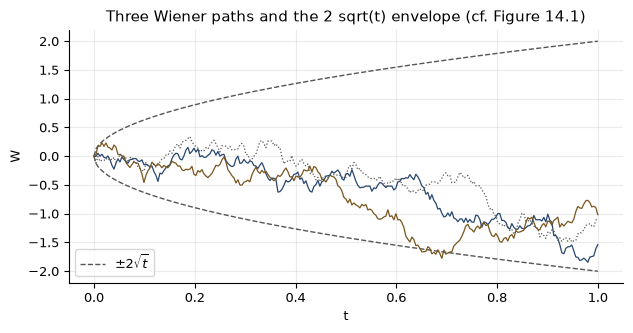

In [2]:
# Example 14.1: a $10 standard deviation over one year
show("two-year s.d. sqrt(100 + 100)", sqrt(100 + 100), "14.14")
show("six-month s.d. 10 sqrt(0.5)", 10 * sqrt(0.5), "7.07")
show("three-month s.d. 10 sqrt(0.25)", 10 * sqrt(0.25), "5.00")

# Build W from independent increments eps sqrt(dt), eq. (14.1), and watch Var[W(T)] track T
rng = np.random.default_rng(1401)
n_paths, n_steps = 20000, 252
dW = rng.standard_normal((n_paths, n_steps)) * sqrt(1.0 / n_steps)
W = np.cumsum(dW, axis=1)
print("simulated (20,000 paths): the variance of W(T) grows with T, the s.d. with sqrt(T)")
for T in (0.25, 0.5, 1.0):
    k = int(round(T * n_steps)) - 1
    print("  T = %.2f   Var[W(T)] = %.4f   s.d. = %.4f   sqrt(T) = %.4f"
          % (T, W[:, k].var(), W[:, k].std(), sqrt(T)))

t = np.linspace(0.0, 1.0, n_steps + 1)
fig, ax = plt.subplots()
ax.plot(t, 2 * np.sqrt(t), color=GRAY, ls="--", lw=1, label=r"$\pm 2\sqrt{t}$")
ax.plot(t, -2 * np.sqrt(t), color=GRAY, ls="--", lw=1)
for i, (c, ls) in enumerate(((BLUE, "-"), (AMBER, "-"), (GRAY, ":"))):
    ax.plot(t, np.concatenate(([0.0], W[i])), color=c, ls=ls, lw=0.9)
ax.set_xlabel("t"); ax.set_ylabel("W"); ax.set_ylim(-2.2, 2.2); ax.legend(loc="lower left")
ax.set_title("Three Wiener paths and the 2 sqrt(t) envelope (cf. Figure 14.1)")
plt.tight_layout(); plt.show()

The cash position of Example 14.2 drifts upward and still has a real chance of running
out. The probability of being *below* zero on a given date peaks and then falls;
the probability of having *touched* zero by that date, from the reflection argument,
only rises, toward $e^{-2ax_0/b^2} = 10.8\%$. The simulation checks the 2.7% within the
year. Testing for a crossing only at the grid dates would miss the crossings between
them and come out low, so each step carries the Brownian-bridge probability of a crossing
inside it.

In [3]:
# Example 14.2: drift a = 20, variance rate b^2 = 900, starting at x0 = 50 ($ millions)
a, b, x0 = 20.0, 30.0, 50.0
show("mean after one year", x0 + a, "70")
show("s.d. after one year", b, "30")
show("s.d. after six months, sqrt(450)", sqrt(450), "21.2")
show("Pr(negative at one year), %", 100 * Phi((0 - 70) / 30.0), "0.98")
show("z at one year", (0 - 70) / 30.0, "-2.333")
show("Pr(negative at six months), %", 100 * Phi(-60 / sqrt(450)), "0.23")
show("z at six months", -60 / sqrt(450), "-2.83")


def touch_prob(T):
    """Probability that x = x0 + a t + b W(t) touches zero by T (the reflection argument)."""
    m, s = a * T, b * sqrt(T)
    return Phi((-x0 - m) / s) + exp(-2 * a * x0 / b ** 2) * Phi((-x0 + m) / s)


show("Pr(touches zero within the year), %", 100 * touch_prob(1.0), "2.7")
show("Pr(ever touches zero), exp(-2 a x0 / b^2), %", 100 * exp(-2 * a * x0 / b ** 2), "10.8")

print()
print("terminal probability against touching probability (the first peaks, the second never falls)")
for T in (0.5, 1, 2.5, 5, 10, 50):
    print("  T = %5.1f   below zero at T: %5.2f%%   touched by T: %5.2f%%"
          % (T, 100 * Phi(-(x0 + a * T) / (b * sqrt(T))), 100 * touch_prob(T)))

# Monte Carlo check of the 2.7%. Testing only at the grid dates misses crossings
# between them, so each step multiplies in the Brownian-bridge probability of
# NOT crossing zero inside the step, 1 - exp(-2 x_i x_{i+1} / (b^2 dt)).
rng = np.random.default_rng(2026)
n_paths, n_steps = 200000, 50
dt = 1.0 / n_steps
x = np.full(n_paths, x0)
survive = np.ones(n_paths)
for _ in range(n_steps):
    x_new = x + a * dt + b * sqrt(dt) * rng.standard_normal(n_paths)
    both_up = (x > 0) & (x_new > 0)
    survive *= np.where(both_up, 1 - np.exp(-2 * x * x_new / (b * b * dt)), 0.0)
    x = x_new
sim("Pr(touches zero within the year), %", 100 * (1 - survive.mean()), "2.7", 0.15)

mean after one year                               70.000000   book        70   ok
s.d. after one year                               30.000000   book        30   ok
s.d. after six months, sqrt(450)                  21.213203   book      21.2   ok
Pr(negative at one year), %                        0.981533   book      0.98   ok
z at one year                                     -2.333333   book    -2.333   ok
Pr(negative at six months), %                      0.233887   book      0.23   ok
z at six months                                   -2.828427   book     -2.83   ok
Pr(touches zero within the year), %                2.700848   book       2.7   ok
Pr(ever touches zero), exp(-2 a x0 / b^2), %      10.836802   book      10.8   ok

terminal probability against touching probability (the first peaks, the second never falls)
  T =   0.5   below zero at T:  0.23%   touched by T:  0.56%
  T =   1.0   below zero at T:  0.98%   touched by T:  2.70%
  T =   2.5   below zero at T:  1.75%   touched

Pr(touches zero within the year), %                2.666374   book       2.7   ok (simulated, +/- 0.15)


## 2. Geometric Brownian motion — Figure 14.2 and Example 14.3

Paths at Figure 14.2's parameters, drawn with the exact step (14.6). They are fresh draws,
not the figure's own paths, but they show the same thing: the paths do not track
$S_0e^{\mu t}$, and a positive $\mu$ does not stop several of them finishing below it.

Example 14.3 then reads the process over one week. The noise is about thirteen and a half
times the drift over a week and about thirty times over a day, which is why $\mu$ cannot
usefully be estimated from history: the last line shows the standard error of a twenty-year
estimate.

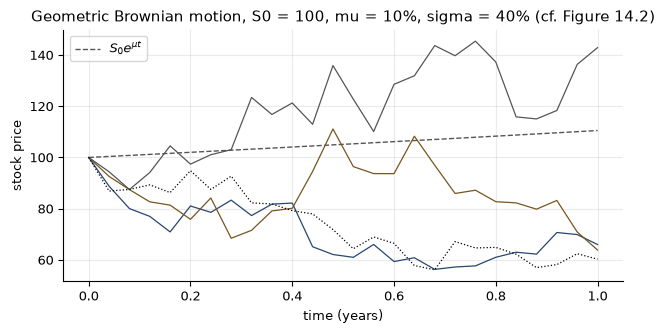

3 of these four paths finish below S0 e^{mu T} = 110.52


In [4]:
# Figure 14.2's parameters: S0 = 100, mu = 10%, sigma = 40%, 25 steps of 0.04 years,
# generated with the exact scheme (14.6), as the figure was. These are fresh draws,
# not the figure's own paths.
S0, mu, sigma = 100.0, 0.10, 0.40
n_steps, dt = 25, 0.04
rng = np.random.default_rng(1402)
eps = rng.standard_normal((4, n_steps))
logS = np.log(S0) + np.cumsum((mu - sigma ** 2 / 2) * dt + sigma * sqrt(dt) * eps, axis=1)
paths = np.hstack([np.full((4, 1), S0), np.exp(logS)])
t = np.arange(n_steps + 1) * dt

fig, ax = plt.subplots()
ax.plot(t, S0 * np.exp(mu * t), color=GRAY, ls="--", lw=1, label=r"$S_0e^{\mu t}$")
for p, (c, ls) in zip(paths, ((BLUE, "-"), (AMBER, "-"), (GRAY, "-"), ("black", ":"))):
    ax.plot(t, p, color=c, ls=ls, lw=0.9)
ax.set_xlabel("time (years)"); ax.set_ylabel("stock price"); ax.legend(loc="upper left")
ax.set_title("Geometric Brownian motion, S0 = 100, mu = 10%, sigma = 40% (cf. Figure 14.2)")
plt.tight_layout(); plt.show()
print("%d of these four paths finish below S0 e^{mu T} = %.2f" % (sum(paths[:, -1] < S0 * exp(mu)), S0 * exp(mu)))

In [5]:
# Example 14.3: S = 50, mu = 16%, sigma = 30%, one week
S, mu_w, sig_w = 50.0, 0.16, 0.30
dt = 1 / 52.0
show("Delta t = 1/52", dt, "0.01923")
show("mean of the weekly return", mu_w * dt, "0.003077")
show("variance of the weekly return", sig_w ** 2 * dt, "0.001731")
show("mean of the weekly return, %", 100 * mu_w * dt, "0.31")
show("s.d. of the weekly return, %", 100 * sig_w * sqrt(dt), "4.16")
show("dollar mean, $", S * mu_w * dt, "0.154")
show("dollar s.d., $", S * sig_w * sqrt(dt), "2.08")
show("noise over drift, one week", sig_w * sqrt(dt) / (mu_w * dt), "13.5")
show("noise over drift, one day (252 a year)", sig_w * sqrt(1 / 252.0) / (mu_w / 252.0), "30")

# a million simulated weeks reproduce the distribution; the drift is the hard part
rng = np.random.default_rng(1403)
weekly = mu_w * dt + sig_w * sqrt(dt) * rng.standard_normal(1_000_000)
sim("simulated mean of the weekly return, %", 100 * weekly.mean(), "0.31", 0.02)
sim("simulated s.d. of the weekly return, %", 100 * weekly.std(), "4.16", 0.02)
years = 20
est = rng.standard_normal(10000) * sig_w / sqrt(years) + mu_w
print("estimating mu from %d years of returns: standard error %.1f%% on a true mu of %.0f%%" % (years, 100 * est.std(), 100 * mu_w))

Delta t = 1/52                                     0.019231   book   0.01923   ok
mean of the weekly return                          0.003077   book  0.003077   ok
variance of the weekly return                      0.001731   book  0.001731   ok
mean of the weekly return, %                       0.307692   book      0.31   ok
s.d. of the weekly return, %                       4.160251   book      4.16   ok
dollar mean, $                                     0.153846   book     0.154   ok
dollar s.d., $                                     2.080126   book      2.08   ok
noise over drift, one week                        13.520817   book      13.5   ok
noise over drift, one day (252 a year)            29.764702   book        30   ok
simulated mean of the weekly return, %             0.305625   book      0.31   ok (simulated, +/- 0.02)
simulated s.d. of the weekly return, %             4.163497   book      4.16   ok (simulated, +/- 0.02)
estimating mu from 20 years of returns: standard error

## 3. The Euler step against the exact step — equations (14.5) and (14.6)

The direct reading of the equation, (14.5), adds a normal amount to the price and can
therefore push it below zero. The exact step (14.6) multiplies by an exponential and
cannot. Both are fed the same draws here, over one step of a full year, where the
difference is easiest to see. The Euler step gets the mean wrong as well, $S_0(1+\mu T)$
in place of $S_0e^{\mu T}$; refining its grid repairs the mean and drives the negative
prices out, while the exact step is right at any step length. The last table prints the
Euler mean's exact value, $S_0(1+\mu T/n)^n$, beside the simulated one, which scatters
around it by about 0.15, the sampling error of 100,000 paths.

In [6]:
# Euler (14.5) against the exact step (14.6), on the same normal draws.
# One step of a full year at Figure 14.2's parameters makes the difference visible.
S0, mu, sigma, T = 100.0, 0.10, 0.40, 1.0
rng = np.random.default_rng(1404)
eps = rng.standard_normal(1_000_000)
euler = S0 + mu * S0 * T + sigma * S0 * eps * sqrt(T)
exact = S0 * np.exp((mu - sigma ** 2 / 2) * T + sigma * eps * sqrt(T))

print("one-year Euler step: %.3f%% of outcomes negative (theory %.3f%%); exact step: %d negative" % (100 * (euler < 0).mean(), 100 * Phi(-(1 + mu * T) / (sigma * sqrt(T))),
                         (exact < 0).mean()))
print("lowest outcome: Euler %.2f, exact %.2f" % (euler.min(), exact.min()))
print("%-30s %10s %10s" % ("", "Euler", "exact"))
print("%-30s %10.3f %10.3f" % ("mean of S_T", euler.mean(), exact.mean()))
print("%-30s %10.3f %10.3f" % ("median of S_T", np.median(euler), np.median(exact)))
print("%-30s %10.3f %10.3f" % ("theory: mean", S0 * (1 + mu * T), S0 * exp(mu * T)))
sim("exact scheme: mean of S_T (E[S_T] = 110.52)", exact.mean(), "110.52", 0.15)
sim("exact scheme: median of S_T (102.02)", np.median(exact), "102.02", 0.15)

# Refine the Euler grid and its mean converges to S0 e^{mu T}; one step gives S0 (1 + mu T)
print("Euler on a finer grid (100,000 paths): the mean approaches 100 e^{0.1} = 110.52")
rng = np.random.default_rng(1405)
for n in (1, 4, 52, 252):
    s = np.full(100000, S0)
    for _ in range(n):
        s = s * (1 + mu * T / n + sigma * sqrt(T / n) * rng.standard_normal(s.size))
    print("  n = %3d   mean %8.3f   theory S0 (1 + mu T / n)^n = %8.3f   Pr(S_T < 0) %.4f%%"
          % (n, s.mean(), S0 * (1 + mu * T / n) ** n, 100 * (s < 0).mean()))

one-year Euler step: 0.297% of outcomes negative (theory 0.298%); exact step: 0 negative
lowest outcome: Euler -84.24, exact 14.63
                                    Euler      exact
mean of S_T                       109.956    110.473
median of S_T                     109.997    102.017
theory: mean                      110.000    110.517
exact scheme: mean of S_T (E[S_T] = 110.52)      110.473028   book    110.52   ok (simulated, +/- 0.15)
exact scheme: median of S_T (102.02)             102.016725   book    102.02   ok (simulated, +/- 0.15)
Euler on a finer grid (100,000 paths): the mean approaches 100 e^{0.1} = 110.52
  n =   1   mean  109.900   theory S0 (1 + mu T / n)^n =  110.000   Pr(S_T < 0) 0.2910%


  n =   4   mean  110.509   theory S0 (1 + mu T / n)^n =  110.381   Pr(S_T < 0) 0.0000%
  n =  52   mean  110.315   theory S0 (1 + mu T / n)^n =  110.506   Pr(S_T < 0) 0.0000%


  n = 252   mean  110.849   theory S0 (1 + mu T / n)^n =  110.515   Pr(S_T < 0) 0.0000%


## 4. Quadratic variation — Figure 14.3 and equation (14.7)

The running sum of squared increments along one Wiener path, sampled on three grids. On the
coarse grids the sum is visibly random; on 10,000 steps it lies almost on the line $t$.
That is the content of $dW^2 = dt$: a statement about the sum, not about any one increment.

10 steps: sum of squared increments                0.455222   book    0.4552   ok
100 steps                                          0.810325   book    0.8103   ok
10,000 steps                                       1.006431   book    1.0064   ok
100 steps, at t = 0.5                              0.417923   book    0.4179   ok
10,000 steps, at t = 0.5                           0.515310   book    0.5153   ok


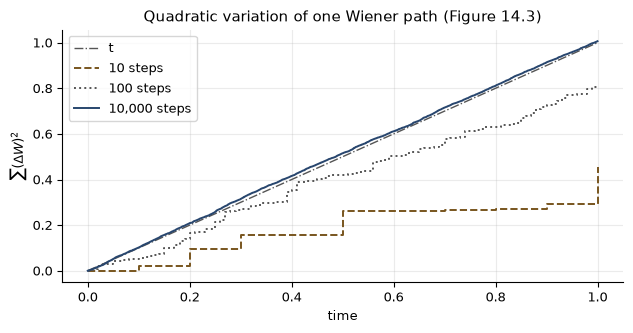

In [7]:
# Figure 14.3 regenerated exactly: one Wiener path on 10,000 steps from Python's own
# generator with seed 1914 (the generator tools/verify/ch14-examples.py uses), then sampled
# on grids of 10, 100 and 10,000 steps.
QV_SEED, FINE = 1914, 10000
gen = random.Random(QV_SEED)
w = [0.0]
for _ in range(FINE):
    w.append(w[-1] + gen.gauss(0.0, 1.0) * sqrt(1.0 / FINE))
w = np.array(w)


def running_qv(n):
    """Running sum of squared increments of w sampled on an n-step grid."""
    coarse = w[:: FINE // n]
    return np.concatenate(([0.0], np.cumsum(np.diff(coarse) ** 2)))


show("10 steps: sum of squared increments", running_qv(10)[-1], "0.4552")
show("100 steps", running_qv(100)[-1], "0.8103")
show("10,000 steps", running_qv(FINE)[-1], "1.0064")
show("100 steps, at t = 0.5", running_qv(100)[50], "0.4179")
show("10,000 steps, at t = 0.5", running_qv(FINE)[5000], "0.5153")

fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], color=GRAY, ls="-.", lw=1, label="t")
ax.step(np.linspace(0, 1, 11), running_qv(10), where="post", color=AMBER, ls="--", lw=1.4,
        label="10 steps")
ax.step(np.linspace(0, 1, 101), running_qv(100), where="post", color=GRAY, ls=":", lw=1.4,
        label="100 steps")
ax.plot(np.linspace(0, 1, FINE + 1), running_qv(FINE), color=BLUE, lw=1.4, label="10,000 steps")
ax.set_xlabel("time"); ax.set_ylabel(r"$\sum(\Delta W)^2$"); ax.legend(loc="upper left")
ax.set_title("Quadratic variation of one Wiener path (Figure 14.3)")
plt.tight_layout(); plt.show()

One squared increment $\varepsilon^2\Delta t$ has mean $\Delta t$ and standard deviation
$\sqrt{2}\,\Delta t$, the same size as its mean, so on its own it is still thoroughly random.
The sum of $T/\Delta t$ of them has mean $T$ and variance $2T\Delta t$, and the table shows
that standard deviation shrinking as the grid is refined.

In [8]:
# A single eps^2 dt is random: mean dt, s.d. sqrt(2) dt. The sum of T/dt of them has
# mean T and variance 2 T dt, which vanishes as dt shrinks.
rng = np.random.default_rng(1406)
dt = 0.01
one = rng.standard_normal(1_000_000) ** 2 * dt
sim("one squared increment: mean / dt", one.mean() / dt, "1", 0.01)
sim("one squared increment: s.d. / (sqrt(2) dt)", one.std() / (sqrt(2) * dt), "1", 0.01)
print("the sum over [0, 1] of n squared increments, 1,000 simulated paths each:")
for n in (10, 100, 1000, 10000):
    dt = 1.0 / n
    sums = (rng.standard_normal((1000, n)) ** 2 * dt).sum(axis=1)
    print("  n = %5d   mean %.4f   s.d. %.4f   theory sqrt(2 T dt) = %.4f"
          % (n, sums.mean(), sums.std(), sqrt(2 * dt)))

one squared increment: mean / dt                   0.999148   book         1   ok (simulated, +/- 0.01)
one squared increment: s.d. / (sqrt(2) dt)         1.001443   book         1   ok (simulated, +/- 0.01)
the sum over [0, 1] of n squared increments, 1,000 simulated paths each:
  n =    10   mean 0.9935   s.d. 0.4492   theory sqrt(2 T dt) = 0.4472
  n =   100   mean 0.9991   s.d. 0.1410   theory sqrt(2 T dt) = 0.1414
  n =  1000   mean 0.9994   s.d. 0.0449   theory sqrt(2 T dt) = 0.0447


  n = 10000   mean 1.0001   s.d. 0.0140   theory sqrt(2 T dt) = 0.0141


## 5. The lognormal property — Example 14.6 and Figure 14.4

Itô's lemma applied to $\ln S$ makes $\ln S_T$ normal, (14.11), and every number below
follows from its mean and variance. The expected price grows at $\mu$, the median at
$\mu - \sigma^2/2$, and the mode lower still; at 40% volatility the stock finishes below
its own expected value 58% of the time. The volatility drag $\sigma^2/2$ is eight
percentage points a year here.

E[S_T] = S0 e^{mu T}, eq. (14.13)                110.517092   book    110.52   ok
E[S_T] from e^{m + s^2/2}, eq. (14.12)           110.517092   book    110.52   ok
median = S0 e^{(mu - sigma^2/2) T}, eq. (14.14)   102.020134   book    102.02   ok
mode = S0 e^{(mu - 3 sigma^2/2) T}                86.935824   book     86.94   ok
z = (ln 1.1052 - 0.02) / 0.40                      0.200066   book      0.20   ok
Pr(S_T > E[S_T]), %                               42.071457   book      42.1   ok
Pr(S_T < E[S_T]), %                               57.928543   book        58   ok
95% interval, lower                               46.579950   book     46.58   ok
95% interval, upper                              223.446092   book    223.45   ok
volatility drag sigma^2/2, percentage points       8.000000   book         8   ok
Figure 14.4: m = ln 100 + 0.02                     4.625170   book   4.62517   ok
Figure 14.4: density at the median                 0.009776   book    0.0098   ok
Figure 14.4: de

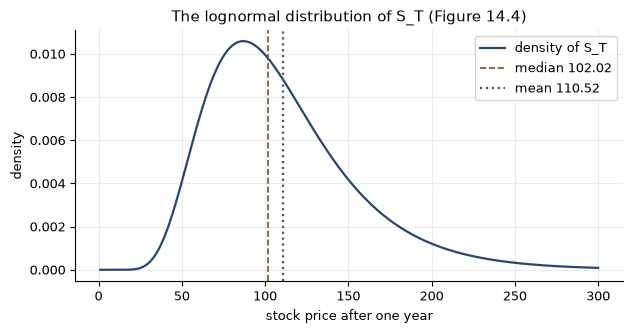

In [9]:
# Example 14.6 and Figure 14.4: S0 = 100, mu = 10%, sigma = 40%, T = 1
S0, mu, sigma, T = 100.0, 0.10, 0.40, 1.0
m, s = log(S0) + (mu - sigma ** 2 / 2) * T, sigma * sqrt(T)       # eq. (14.11)
show("E[S_T] = S0 e^{mu T}, eq. (14.13)", S0 * exp(mu * T), "110.52")
show("E[S_T] from e^{m + s^2/2}, eq. (14.12)", exp(m + s * s / 2), "110.52")
show("median = S0 e^{(mu - sigma^2/2) T}, eq. (14.14)", exp(m), "102.02")
show("mode = S0 e^{(mu - 3 sigma^2/2) T}", S0 * exp((mu - 1.5 * sigma ** 2) * T), "86.94")
z = (log(1.1052) - 0.02) / 0.40
show("z = (ln 1.1052 - 0.02) / 0.40", z, "0.20")
show("Pr(S_T > E[S_T]), %", 100 * (1 - Phi(z)), "42.1")
show("Pr(S_T < E[S_T]), %", 100 * Phi(z), "58")
show("95% interval, lower", exp(m - 1.96 * s), "46.58")
show("95% interval, upper", exp(m + 1.96 * s), "223.45")
show("volatility drag sigma^2/2, percentage points", 100 * sigma ** 2 / 2, "8")
show("Figure 14.4: m = ln 100 + 0.02", m, "4.62517")


def density(x):
    return np.exp(-(np.log(x) - m) ** 2 / (2 * s * s)) / (x * s * sqrt(2 * pi))


show("Figure 14.4: density at the median", density(102.02), "0.0098")
show("Figure 14.4: density at the mean", density(110.52), "0.0088")

# the same answers from a million simulated outcomes
rng = np.random.default_rng(1407)
ST = np.exp(m + s * rng.standard_normal(1_000_000))
sim("simulated mean", ST.mean(), "110.52", 0.2)
sim("simulated median", np.median(ST), "102.02", 0.2)
sim("simulated Pr(S_T > 110.52), %", 100 * (ST > 110.52).mean(), "42.1", 0.2)

x = np.linspace(1, 300, 600)
fig, ax = plt.subplots()
ax.plot(x, density(x), color=BLUE, lw=1.6, label="density of S_T")
ax.axvline(exp(m), color=AMBER, ls="--", lw=1.2, label="median %.2f" % exp(m))
ax.axvline(S0 * exp(mu * T), color=GRAY, ls=":", lw=1.6, label="mean %.2f" % (S0 * exp(mu * T)))
ax.set_xlabel("stock price after one year"); ax.set_ylabel("density"); ax.legend()
ax.set_title("The lognormal distribution of S_T (Figure 14.4)")
plt.tight_layout(); plt.show()

## 6. Arithmetic and geometric averages — Example 14.4, and the $\sigma/16$ rule

The arithmetic average of five annual returns is 10.0%; an investor who held throughout
earned 8.93% a year compounded, which is 8.56% a year in log returns. The arithmetic average
exceeds the average log return by 1.44 percentage points, which matches half the sample
variance of the returns: the $\sigma^2/2$ of notebook section 5, seen in five numbers. Section 14.6's
$\sigma/16$ rule follows at the end of the cell.

In [10]:
# Example 14.4: five annual returns
r = np.array([0.30, -0.10, 0.20, -0.05, 0.15])
wealth = np.prod(1 + r)
show("arithmetic average, %", 100 * r.mean(), "10.0")
show("terminal wealth", wealth, "1.53387")
show("compounded annual return, %", 100 * (wealth ** 0.2 - 1), "8.93")
show("average log return, %", 100 * np.log(1 + r).mean(), "8.56")
show("arithmetic minus log average, pp", 100 * (r.mean() - np.log(1 + r).mean()), "1.44")
show("sample variance of the simple returns", r.var(ddof=1), "0.0288")
show("half of it, pp", 100 * r.var(ddof=1) / 2, "1.44")

# Section 14.6: the sigma/16 rule
show("sqrt(252)", sqrt(252), "15.9")
show("daily s.d. at 32% a year, %", 32 / sqrt(252), "2")
show("a 6% move, in daily s.d. (32/16 = 2%)", 6 / (32 / 16.0), "3")

arithmetic average, %                             10.000000   book      10.0   ok
terminal wealth                                    1.533870   book   1.53387   ok
compounded annual return, %                        8.932560   book      8.93   ok
average log return, %                              8.555879   book      8.56   ok
arithmetic minus log average, pp                   1.444121   book      1.44   ok
sample variance of the simple returns              0.028750   book    0.0288   ok
half of it, pp                                     1.437500   book      1.44   ok
sqrt(252)                                         15.874508   book      15.9   ok
daily s.d. at 32% a year, %                        2.015811   book         2   ok
a 6% move, in daily s.d. (32/16 = 2%)              3.000000   book         3   ok


## 7. Two sources of uncertainty — Example 14.7

The ratio of two geometric Brownian motions is one too, with volatility (14.19). The
simulation draws correlated shocks and measures the standard deviation of the log ratio
directly.

In [11]:
# Example 14.7: the volatility of a ratio, eq. (14.19)
s1, s2 = 0.20, 0.12
for rho, printed in ((0.4, "18.8"), (-0.4, "27.1")):
    show("sigma_G at rho = %+.1f, %%" % rho, 100 * sqrt(s1 ** 2 + s2 ** 2 - 2 * rho * s1 * s2), printed)

# check by simulation: log(S1/S2) over one year, from correlated draws
rng = np.random.default_rng(1408)
z1 = rng.standard_normal(1_000_000)
for rho, printed in ((0.4, "18.8"), (-0.4, "27.1")):
    z2 = rho * z1 + sqrt(1 - rho ** 2) * rng.standard_normal(z1.size)
    sim("simulated s.d. of ln(S1/S2) at rho = %+.1f, %%" % rho, 100 * (s1 * z1 - s2 * z2).std(),
        printed, 0.1)

sigma_G at rho = +0.4, %                          18.761663   book      18.8   ok
sigma_G at rho = -0.4, %                          27.129320   book      27.1   ok
simulated s.d. of ln(S1/S2) at rho = +0.4, %      18.766202   book      18.8   ok (simulated, +/- 0.1)
simulated s.d. of ln(S1/S2) at rho = -0.4, %      27.135878   book      27.1   ok (simulated, +/- 0.1)


## 8. The leveraged-ETF case study

A fund delivering $k$ times the index's daily return has median growth
$k\mu - k^2\sigma^2/2$, against $k(\mu - \sigma^2/2)$ for $k$ times the index's own. The
chapter's figures are before financing, fees and rebalancing costs, and so are these. The
simulation builds a fund that really does deliver twice the index's return each trading
day and reads off its median after a year: daily compounding lands close to the
continuous-time answer.

In [12]:
# The leveraged-ETF case study: median growth k mu - k^2 sigma^2 / 2, eq. (14.14) with
# drift k mu and volatility k sigma. The chapter's figures are before financing, fees and
# rebalancing costs; financing the k - 1 borrowed units would lower the drift by (k - 1) r.
mu = 0.08
for sigma, idx_p, fund_p in ((0.25, "5.0", "3.6"), (0.40, "0", "-14.8")):
    show("sigma = %.0f%%: index median return, %%" % (100 * sigma),
         100 * (exp(mu - sigma ** 2 / 2) - 1), idx_p)
    show("sigma = %.0f%%: 2x fund median return, %%" % (100 * sigma),
         100 * (exp(2 * mu - 4 * sigma ** 2 / 2) - 1), fund_p)
for k in (2, 3):
    sigma = 0.25
    gap = k * (mu - sigma ** 2 / 2) - (k * mu - k * k * sigma ** 2 / 2)
    print("k = %d: shortfall %.5f = k(k - 1)/2 x sigma^2 = %.1f x %.4f" % (k, gap, k * (k - 1) / 2, sigma ** 2))

# a fund that really does deliver 2x the index's return each trading day, simulated
rng = np.random.default_rng(1409)
n_paths, days = 100000, 252
for sigma, fund_p in ((0.25, "3.6"), (0.40, "-14.8")):
    dt = 1.0 / days
    index = np.ones(n_paths)
    fund = np.ones(n_paths)
    for _ in range(days):
        step = np.exp((mu - sigma ** 2 / 2) * dt + sigma * sqrt(dt) * rng.standard_normal(n_paths))
        index *= step
        fund *= 1 + 2 * (step - 1)
    sim("daily 2x fund, sigma = %.0f%%: median return, %%" % (100 * sigma),
        100 * (np.median(fund) - 1), fund_p, 0.5)
    print("    simulated medians: index %.2f%%, 2x fund %.2f%%" % (100 * (np.median(index) - 1), 100 * (np.median(fund) - 1)))

sigma = 25%: index median return, %                4.995783   book       5.0   ok
sigma = 25%: 2x fund median return, %              3.561971   book       3.6   ok
sigma = 40%: index median return, %                0.000000   book         0   ok
sigma = 40%: 2x fund median return, %            -14.785621   book     -14.8   ok
k = 2: shortfall 0.06250 = k(k - 1)/2 x sigma^2 = 1.0 x 0.0625
k = 3: shortfall 0.18750 = k(k - 1)/2 x sigma^2 = 3.0 x 0.0625


daily 2x fund, sigma = 25%: median return, %       3.604218   book       3.6   ok (simulated, +/- 0.5)
    simulated medians: index 5.03%, 2x fund 3.60%


daily 2x fund, sigma = 40%: median return, %     -14.536889   book     -14.8   ok (simulated, +/- 0.5)
    simulated medians: index 0.13%, 2x fund -14.54%


## 9. Fractional Brownian motion — Section 14.13, Example 14.8, Figure 14.5

The correlation between successive equal increments is $2^{2H-1} - 1$, (14.22), checked
here against the covariance (14.20) directly. Example 14.8 is the variance rule
$T^{2H}$ at $H = 0.1$: doubling the horizon adds 7% to the standard deviation, not 41%, and
the square-root rule overstates a one-year standard deviation built from daily data by
$252^{0.4} = 9.1$ times.

In [13]:
# Fractional Brownian motion: correlation of successive equal increments, eq. (14.22),
# and Example 14.8 at H = 0.1


def fbm_cov(s, t, H):
    """Covariance of fractional Brownian motion, eq. (14.20)."""
    return 0.5 * (s ** (2 * H) + t ** (2 * H) - abs(t - s) ** (2 * H))


for H, printed in ((0.1, "-0.43"), (0.5, "0"), (0.9, "0.74")):
    show("rho = 2^{2H-1} - 1 at H = %.1f" % H, 2 ** (2 * H - 1) - 1, printed)
    direct = (fbm_cov(1.0, 2.0, H) - fbm_cov(1.0, 1.0, H)) / fbm_cov(1.0, 1.0, H)
    print("    %s %+.6f" % ("from the covariance (14.20) directly:", direct))

show("two-year variance 2^{0.2}", 2 ** 0.2, "1.15")
show("two-year s.d. 2^{0.1}", 2 ** 0.1, "1.07")
show("Wiener two-year s.d. sqrt(2)", sqrt(2), "1.41")
show("annualizing factor 252^{0.1}", 252 ** 0.1, "1.74")
show("annualizing factor 252^{0.5}", 252 ** 0.5, "15.9")
show("square-root rule overstates by 252^{0.4}", 252 ** 0.4, "9.1")

rho = 2^{2H-1} - 1 at H = 0.1                     -0.425651   book     -0.43   ok
    from the covariance (14.20) directly: -0.425651
rho = 2^{2H-1} - 1 at H = 0.5                      0.000000   book         0   ok
    from the covariance (14.20) directly: +0.000000
rho = 2^{2H-1} - 1 at H = 0.9                      0.741101   book      0.74   ok
    from the covariance (14.20) directly: +0.741101
two-year variance 2^{0.2}                          1.148698   book      1.15   ok
two-year s.d. 2^{0.1}                              1.071773   book      1.07   ok
Wiener two-year s.d. sqrt(2)                       1.414214   book      1.41   ok
annualizing factor 252^{0.1}                       1.738361   book      1.74   ok
annualizing factor 252^{0.5}                      15.874508   book      15.9   ok
square-root rule overstates by 252^{0.4}           9.131880   book       9.1   ok


Figure 14.5 is regenerated exactly. A fractional path cannot be built one independent
increment at a time, so the covariance matrix (14.20) on the grid is factored by
Cholesky, $LL^{\top} = C$, and $L$ multiplies one vector of normal draws. The same draws
go into all three values of $H$, which is why the three curves are recognizably the same
randomness. At $H = 0.5$ the result is the plain cumulative sum of the scaled draws, a
Wiener path. The last table shows why there is no $dB^2 = dt$: the sum of squared
increments scales as $n^{1-2H}$, large for the rough path and small for the persistent one.

H = 0.1 at t = 0.02                                0.824665   book    0.8247   ok
H = 0.1 at t = 1                                   0.350284   book    0.3503   ok
H = 0.5 at t = 0.02                                0.172461   book    0.1725   ok
H = 0.5 at t = 1                                   0.400148   book    0.4001   ok
H = 0.9 at t = 0.02                                0.036066   book    0.0361   ok
H = 0.9 at t = 1                                   0.678668   book    0.6787   ok
H = 0.5 path against the cumulative sum of the draws: largest gap 2.4e-15
sum of the 50 squared increments on [0, 1]:
  H = 0.1   this path  16.8504   T^{2H} n^{1-2H} =  22.8653
  H = 0.5   this path   0.8334   T^{2H} n^{1-2H} =   1.0000
  H = 0.9   this path   0.0292   T^{2H} n^{1-2H} =   0.0437


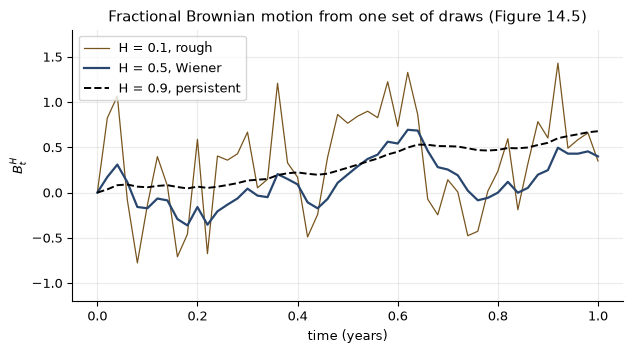

In [14]:
# Figure 14.5 regenerated exactly: 50 standard normal draws from Python's generator with
# seed 14 (as tools/verify/ch14-fbm.py draws them), multiplied by the Cholesky factor of
# the covariance (14.20) on the grid t = 0.02, ..., 1 for each H. One vector of draws,
# three kernels.
n, T = 50, 1.0
gen = random.Random(14)
z = np.array([gen.gauss(0.0, 1.0) for _ in range(n)])
grid = T * np.arange(1, n + 1) / n
fbm = {}
for H in (0.1, 0.5, 0.9):
    C = np.array([[fbm_cov(s, t, H) for t in grid] for s in grid])
    L = np.linalg.cholesky(C)
    fbm[H] = np.concatenate(([0.0], L @ z))

show("H = 0.1 at t = 0.02", fbm[0.1][1], "0.8247")
show("H = 0.1 at t = 1", fbm[0.1][-1], "0.3503")
show("H = 0.5 at t = 0.02", fbm[0.5][1], "0.1725")
show("H = 0.5 at t = 1", fbm[0.5][-1], "0.4001")
show("H = 0.9 at t = 0.02", fbm[0.9][1], "0.0361")
show("H = 0.9 at t = 1", fbm[0.9][-1], "0.6787")
print("H = 0.5 path against the cumulative sum of the draws: largest gap %.1e" % np.abs(fbm[0.5][1:] - np.cumsum(z) * sqrt(T / n)).max())

# the sum of squared increments: about T^{2H} n^{1 - 2H}, so there is no dB^2 = dt
print("sum of the 50 squared increments on [0, 1]:")
for H in (0.1, 0.5, 0.9):
    print("  H = %.1f   this path %8.4f   T^{2H} n^{1-2H} = %8.4f"
          % (H, (np.diff(fbm[H]) ** 2).sum(), T ** (2 * H) * n ** (1 - 2 * H)))

tt = np.concatenate(([0.0], grid))
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(tt, fbm[0.1], color=AMBER, lw=0.9, label="H = 0.1, rough")
ax.plot(tt, fbm[0.5], color=BLUE, lw=1.6, label="H = 0.5, Wiener")
ax.plot(tt, fbm[0.9], color="black", ls="--", lw=1.4, label="H = 0.9, persistent")
ax.set_xlabel("time (years)"); ax.set_ylabel(r"$B^H_t$"); ax.set_ylim(-1.2, 1.8)
ax.legend(loc="upper left"); ax.set_title("Fractional Brownian motion from one set of draws (Figure 14.5)")
plt.tight_layout(); plt.show()